In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns",50)
pd.set_option("display.float_format","{:.2f}".format)

print("Libraries loaded.")

Libraries loaded.


In [5]:
df=df_raw=pd.read_csv(r"C:\Users\rampr\Downloads\bikes.csv")

In [6]:
df_raw["owner"].unique()

<StringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

In [7]:
df_raw.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [8]:
df_raw.duplicated().sum()

np.int64(0)

In [9]:
df_raw.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [10]:
df_raw['price'].describe()

count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [11]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [12]:
df_raw[['kms_driven','mileage','power']].columns

Index(['kms_driven', 'mileage', 'power'], dtype='str')

In [13]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value=str(value).replace(',','')
    number='' #string
    dot_used=False

    for i in value:
        if i.isdigit():
            number+=i
        elif i=='.' and not dot_used:
            dot_used=True
        elif number:
            break
    return float(number) if number else np.nan


In [14]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [15]:
column_name=['mileage', 'power', 'price', 'model_year', 'kms_driven']
for i in column_name:
    df_raw[i]= df_raw[i].apply(get_number)

In [16]:
df_raw

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [17]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   model_name  7857 non-null   str    
 1   model_year  7857 non-null   float64
 2   kms_driven  7854 non-null   float64
 3   owner       7857 non-null   str    
 4   location    7838 non-null   str    
 5   mileage     7083 non-null   float64
 6   power       7826 non-null   float64
 7   price       7857 non-null   float64
dtypes: float64(5), str(3)
memory usage: 491.2 KB


In [18]:
df_raw.duplicated().sum()

np.int64(0)

In [19]:
df=df_raw.dropna(subset='price')

In [20]:
df=df[df['price']>0]

In [21]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982.00,22000.00,first owner,pune,NaN,NaN,150000.00
1716,Royal Enfield Bullet 350 cc 1982,1982.00,16245.00,first owner,delhi,NaN,NaN,70000.00
2211,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,first owner,noida,35.00,2319.00,55000.00
2487,Royal Enfield Bullet 350 cc 1982,1982.00,3000.00,second owner,lalitpur,NaN,NaN,130000.00
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978.00,85000.00,first owner,chikamaglur,NaN,NaN,100000.00
2714,Royal Enfield Bullet 350 cc 1982,1982.00,21000.00,first owner,nashik,NaN,NaN,170000.00
3088,Royal Enfield Bullet 350 cc 1982,1982.00,10000.00,first owner,mumbai,NaN,NaN,60000.00
3429,Royal Enfield‎ Bullet 350cc 1970,1970.00,5000.00,third owner,pune,25.00,1980.00,190000.00
4174,Royal Enfield Standard 350cc 1985,1985.00,40.00,third owner,kolhapur,40.00,18.00,125000.00
4258,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,third owner,khalilabad,35.00,2319.00,55000.00


In [22]:
pd.Timestamp.today().year

2026

In [23]:
if 'model_year' in df.columns:
    current_year= pd.Timestamp.today().year
    df['model_year']= df['model_year'].between(1998, current_year)

In [24]:
df['price'].mean()

np.float64(107214.3539483772)

In [25]:
df['location'].isnull

<bound method Series.isnull of 0         hyderabad
1         hyderabad
2         hyderabad
3       pondicherry
4         bangalore
           ...     
7852           agra
7853          delhi
7854      bangalore
7855      bangalore
7856        chennai
Name: location, Length: 7826, dtype: str>

In [26]:
for col in ["kms_driven","mileage","power" ]:
    if col in df.columns:
        df.loc[df[col]<0,col] =np.nan

In [27]:
df_clean =df.copy

In [28]:
if "model_year" in df.columns:
    current_year = pd.Timestamp.today().year
    df["bike_age"] = current_year - df["model_year"]

In [36]:
df_clean= df.copy()
df_clean.to_csv("bikes_",index=False)
print('cleand dataset')

cleand dataset


In [52]:
df_clean['price'].describe

<bound method Series.describe of 0       63500.00
1      115000.00
2      300000.00
3      100000.00
4      197500.00
          ...   
7852    55000.00
7853    28000.00
7854    61740.00
7855    49000.00
7856    65000.00
Name: price, Length: 7826, dtype: float64>

In [38]:
df_clean['price'].skew

<bound method Series.skew of 0       63500.00
1      115000.00
2      300000.00
3      100000.00
4      197500.00
          ...   
7852    55000.00
7853    28000.00
7854    61740.00
7855    49000.00
7856    65000.00
Name: price, Length: 7826, dtype: float64>

<Axes: xlabel='price', ylabel='Count'>

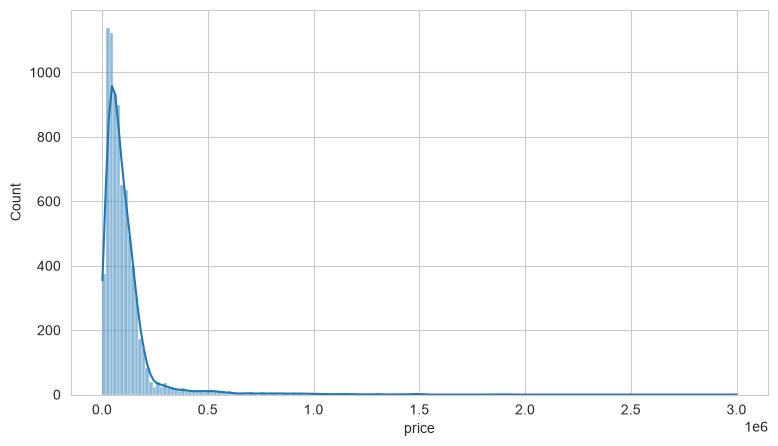

In [53]:
plt.figure(figsize=(9,5))
sns.histplot(data =df_clean,x='price', kde=True)

<Axes: xlabel='price'>

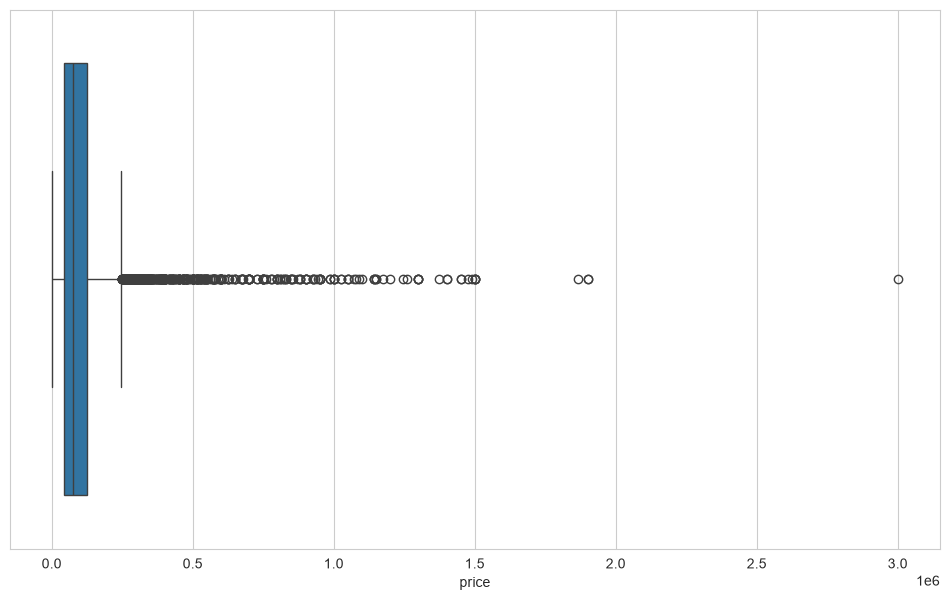

In [65]:
plt.figure(figsize=(12,7))
sns.boxplot(data =df_clean,x='price')

In [47]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [56]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [57]:
df_clean['brand'].unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [49]:
df_clean['brand'].str.lower().unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [63]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median', ascending= False)

In [64]:
brand_top_10

,brand,median,mean,count
5,ducati,907293.50,976293.69,16
22,triumph,800000.00,843183.25,36
15,kawasaki,465000.00,496517.70,67
7,harley-davidson,450000.00,512722.60,171
2,benelli,260000.00,301581.89,53
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
16,ktm,147000.00,150354.56,491
24,um,125000.00,128446.01,128


<Axes: xlabel='brand', ylabel='median'>

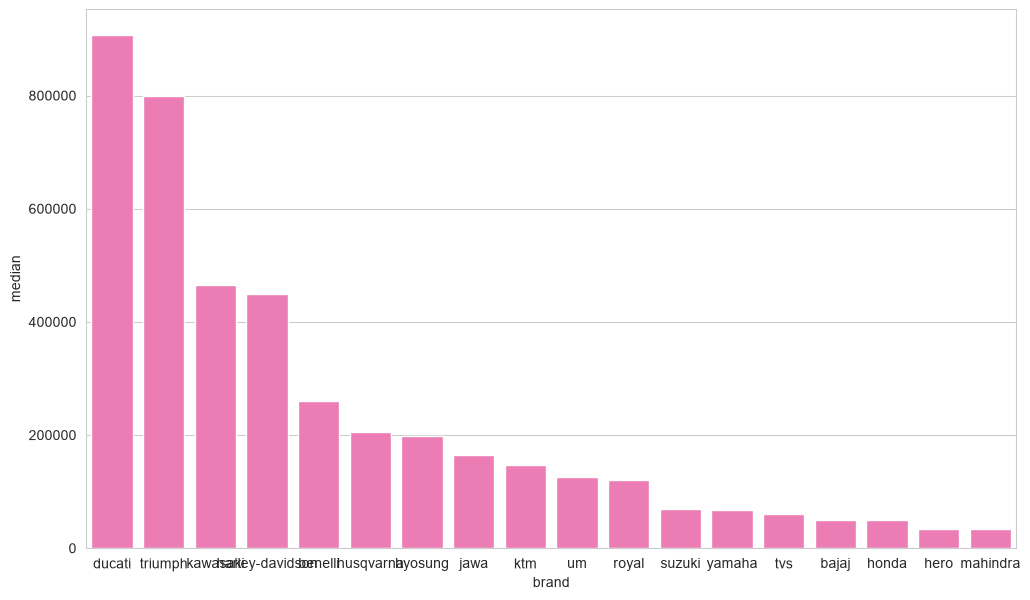

In [67]:
plt.figure(figsize=(12,7))
sns.barplot(data=brand_top_10, x='brand',y='median',color='hotpink')

In [69]:
df_clean [['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.00,-0.11
price,-0.11,1.00


<Axes: xlabel='kms_driven', ylabel='price'>

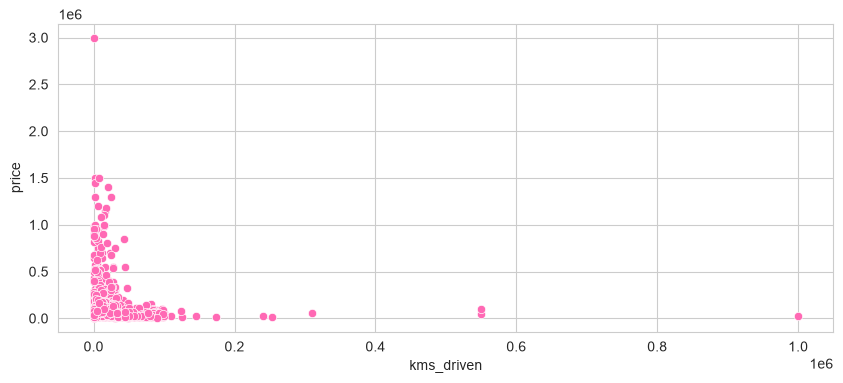

In [76]:
plot_data= df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000, random_state=42)

plt.figure(figsize=(10,4))
sns.scatterplot(data= plot_data,x='kms_driven', y='price',color='hotpink')    

<Axes: xlabel='kms_driven', ylabel='price'>

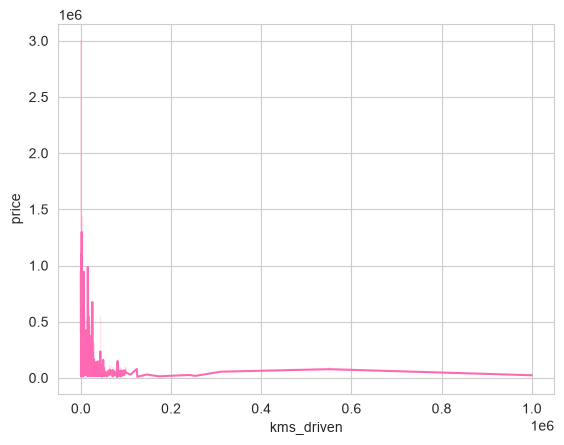

In [78]:
sns.lineplot(data = plot_data, x='kms_driven',y='price',color='hotpink')

<Axes: xlabel='bike_age', ylabel='price'>

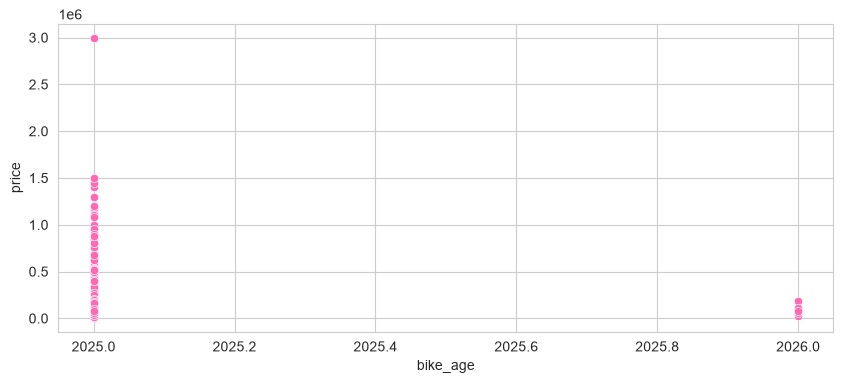

In [79]:
plot_data= df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000, random_state=42)

plt.figure(figsize=(10,4))
sns.scatterplot(data= plot_data,x='bike_age', y='price',color='hotpink')    

<Axes: >

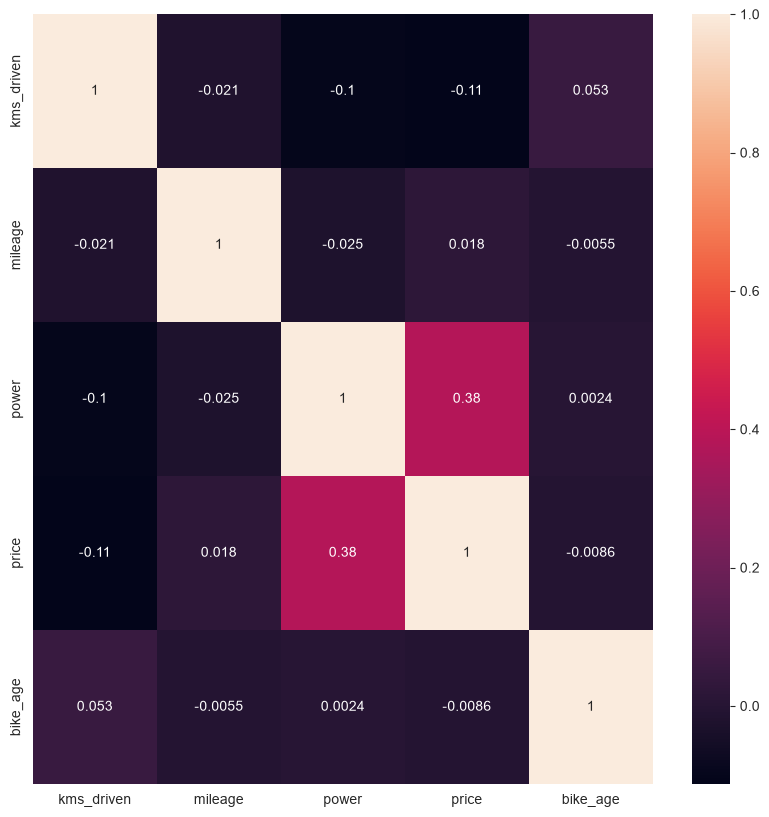

In [81]:
numeric_df = df_clean.select_dtypes(include='number')
plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(), annot= True)

In [82]:
df_clean.dropna(inplace= True)

C:\Users\rampr\AppData\Local\Temp\ipykernel_29972\265570733.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(inplace= True)


In [83]:
df_clean.reset_index(inplace= True)

C:\Users\rampr\AppData\Local\Temp\ipykernel_29972\152758419.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.reset_index(inplace= True)


In [87]:
data=df_clean.drop(['model_name','location'],axis=1)

In [88]:
data.columns

Index(['index', 'model_year', 'kms_driven', 'owner', 'mileage', 'power',
       'price', 'bike_age', 'brand'],
      dtype='str')

In [92]:
x =data[['model_year','kms_driven', 'owner','mileage','power','bike_age','brand']]
y =data['price']

In [94]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test= train_test_split(x,y, random_state=42, test_size=0.2)

In [95]:
numerical_column=x.select_dtypes(include='number').columns
categorical_column=x.select_dtypes(exclude='number').columns

In [96]:
numeric_pipeline = Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical_pipeline= Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                                  ('ohe',OneHotEncoder(handle_unknown='ignore'))])